# **LAPTOP PRICE PREDICTION**
**AI101 Mini-Project** | Team no.: `85` | Members: `4`

# **LINEAR REGRESSION**
to predict the price of a laptop from its features.

In [1]:
# Cell 1: Import the libraries we need

import pandas as pd                  # Read and work with tabular data
import numpy as np                   # Numerical operations
import matplotlib.pyplot as plt      # Graphs and visualizations
import seaborn as sns                # Heatmap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Display graphs inside the notebook
%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Cell 2: Read the dataset
df = pd.read_csv("data/laptop_data.csv")
print("Dataset shape (rows, columns):", df.shape)
df.head()

Dataset shape (rows, columns): (1303, 12)


,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [3]:
# Cell 3: Inspect the dataset

print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nData types and missing-value overview:")
df.info()

print("\nSummary of numeric columns:")
display(df.describe())

Dataset dimensions: (1303, 12)

Column names:
['Unnamed: 0', 'Company', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price']

First five rows:


,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080



Data types and missing-value overview:
<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1303 non-null   int64  
 1   Company           1303 non-null   str    
 2   TypeName          1303 non-null   str    
 3   Inches            1303 non-null   float64
 4   ScreenResolution  1303 non-null   str    
 5   Cpu               1303 non-null   str    
 6   Ram               1303 non-null   str    
 7   Memory            1303 non-null   str    
 8   Gpu               1303 non-null   str    
 9   OpSys             1303 non-null   str    
 10  Weight            1303 non-null   str    
 11  Price             1303 non-null   float64
dtypes: float64(2), int64(1), str(9)
memory usage: 122.3 KB

Summary of numeric columns:


,Unnamed: 0,Inches,Price
count,1303.00000,1303.000000,1303.000000
mean,651.00000,15.017191,59870.042910
std,376.28801,1.426304,37243.201786
min,0.00000,10.100000,9270.720000
25%,325.50000,14.000000,31914.720000
50%,651.00000,15.600000,52054.560000
75%,976.50000,15.600000,79274.246400
max,1302.00000,18.400000,324954.720000


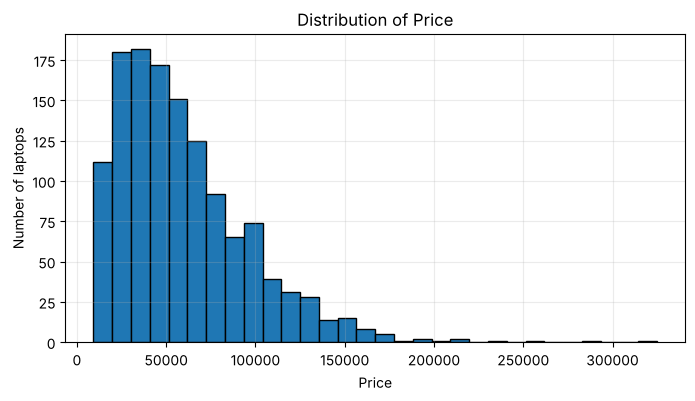

In [4]:
# Cell 4: Plot a histogram of the price

plt.figure(figsize=(8, 4))
plt.hist(df["Price"], bins=30, edgecolor="black")
plt.title("Distribution of Price")
plt.xlabel("Price")
plt.ylabel("Number of laptops")
plt.grid(alpha=0.25)
plt.show()

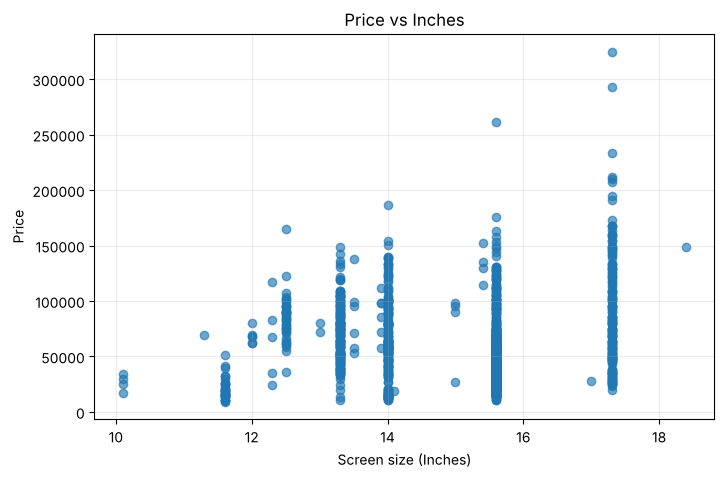

In [5]:
# Cell 5: Scatter plot of screen size versus price

plt.figure(figsize=(8, 5))
plt.scatter(df["Inches"], df["Price"], alpha=0.65)
plt.title("Price vs Inches")
plt.xlabel("Screen size (Inches)")
plt.ylabel("Price")
plt.grid(alpha=0.25)
plt.show()

In [6]:
# Cell 6: Remove the row-number column and remove the units from Ram and Weight

data = df.copy()
data = data.drop(columns=["Unnamed: 0"])

data["Ram"] = data["Ram"].str.replace("GB", "").astype(int)
data["Weight"] = data["Weight"].str.replace("kg", "").astype(float)

display(data[["Ram", "Weight", "Price"]].head())

,Ram,Weight,Price
0,8,1.37,71378.6832
1,8,1.34,47895.5232
2,8,1.86,30636.0000
3,16,1.83,135195.3360
4,8,1.37,96095.8080


In [7]:
# Cell 7: Create screen features

data["Touchscreen"] = data["ScreenResolution"].str.contains("Touchscreen").astype(int)
data["IPS"] = data["ScreenResolution"].str.contains("IPS").astype(int)

# The last word is the resolution, for example "1920x1080"
resolution = data["ScreenResolution"].str.split().str[-1].str.split("x", expand=True).astype(int)
data["PPI"] = ((resolution[0] ** 2 + resolution[1] ** 2) ** 0.5) / data["Inches"]

display(data[["Touchscreen", "IPS", "PPI"]].head())

,Touchscreen,IPS,PPI
0,0,1,226.983005
1,0,0,127.677940
2,0,0,141.211998
3,0,1,220.534624
4,0,1,226.983005


In [8]:
# Cell 8: Group the CPU, Memory, GPU and OS columns

def get_cpu_type(cpu):
    if "Core i7" in cpu:
        return "Intel i7"
    elif "Core i5" in cpu:
        return "Intel i5"
    elif "Core i3" in cpu:
        return "Intel i3"
    elif "Intel" in cpu:
        return "Other Intel"
    else:
        return "AMD"


def get_storage(memory, kind):
    # Adds up the size (in GB) of one storage type, "SSD" or "HDD"
    # Example: "256GB SSD + 1TB HDD" -> SSD = 256, HDD = 1000
    total = 0.0
    for part in memory.split("+"):
        part = part.strip()
        if kind in part:
            size_text = part.split()[0]            # for example "256GB" or "1TB"
            if size_text.endswith("TB"):
                total = total + float(size_text[:-2]) * 1000
            else:
                total = total + float(size_text[:-2])
    return total


def get_os_type(os_name):
    if "Windows" in os_name:
        return "Windows"
    elif os_name == "macOS" or os_name == "Mac OS X":
        return "Mac"
    else:
        return "Other"


data["CpuType"] = data["Cpu"].apply(get_cpu_type)
data["SSD"] = data["Memory"].apply(lambda m: get_storage(m, "SSD"))
data["HDD"] = data["Memory"].apply(lambda m: get_storage(m, "HDD"))
data["GpuBrand"] = data["Gpu"].str.split().str[0]
data["OS"] = data["OpSys"].apply(get_os_type)

# Remove the old text columns
data = data.drop(columns=["ScreenResolution", "Cpu", "Memory", "Gpu", "OpSys"])
data.head()

,Company,TypeName,Inches,Ram,Weight,Price,Touchscreen,IPS,PPI,CpuType,SSD,HDD,GpuBrand,OS
0,Apple,Ultrabook,13.3,8,1.37,71378.6832,0,1,226.983005,Intel i5,128.0,0.0,Intel,Mac
1,Apple,Ultrabook,13.3,8,1.34,47895.5232,0,0,127.677940,Intel i5,0.0,0.0,Intel,Mac
2,HP,Notebook,15.6,8,1.86,30636.0000,0,0,141.211998,Intel i5,256.0,0.0,Intel,Other
3,Apple,Ultrabook,15.4,16,1.83,135195.3360,0,1,220.534624,Intel i7,512.0,0.0,AMD,Mac
4,Apple,Ultrabook,13.3,8,1.37,96095.8080,0,1,226.983005,Intel i5,256.0,0.0,Intel,Mac


In [9]:
# Cell 9: Check missing values and duplicate rows

print("Missing values in each column:")
print(data.isnull().sum())
print("\nDuplicate rows:", data.duplicated().sum())

Missing values in each column:
Company        0
TypeName       0
Inches         0
Ram            0
Weight         0
Price          0
Touchscreen    0
IPS            0
PPI            0
CpuType        0
SSD            0
HDD            0
GpuBrand       0
OS             0
dtype: int64

Duplicate rows: 30


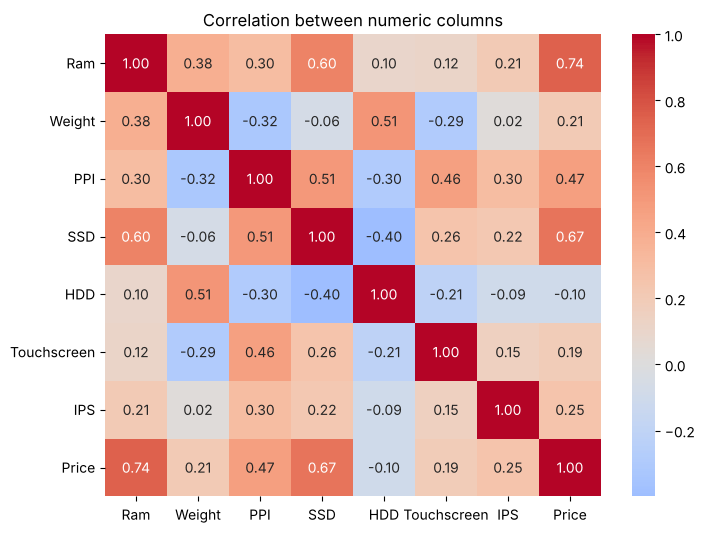

Correlation with Price:
Ram            0.74
SSD            0.67
PPI            0.47
IPS            0.25
Weight         0.21
Touchscreen    0.19
HDD           -0.10
Name: Price, dtype: float64


In [10]:
# Cell 10: Correlation between numeric columns

number_cols = ["Ram", "Weight", "PPI", "SSD", "HDD", "Touchscreen", "IPS", "Price"]
corr = data[number_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric columns")
plt.show()

print("Correlation with Price:")
print(corr["Price"].drop("Price").sort_values(ascending=False).round(2))

In [11]:
# Cell 11: Convert text columns into numbers

data_encoded = pd.get_dummies(data, drop_first=True, dtype=int)

print("Dataset shape after encoding:", data_encoded.shape)
data_encoded.head()

Dataset shape after encoding: (1303, 41)


,Inches,Ram,Weight,Price,Touchscreen,IPS,PPI,SSD,HDD,Company_Apple,Company_Asus,Company_Chuwi,Company_Dell,Company_Fujitsu,Company_Google,Company_HP,Company_Huawei,Company_LG,Company_Lenovo,Company_MSI,Company_Mediacom,Company_Microsoft,Company_Razer,Company_Samsung,Company_Toshiba,Company_Vero,Company_Xiaomi,TypeName_Gaming,TypeName_Netbook,TypeName_Notebook,TypeName_Ultrabook,TypeName_Workstation,CpuType_Intel i3,CpuType_Intel i5,CpuType_Intel i7,CpuType_Other Intel,GpuBrand_ARM,GpuBrand_Intel,GpuBrand_Nvidia,OS_Other,OS_Windows
0,13.3,8,1.37,71378.6832,0,1,226.983005,128.0,0.0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0
1,13.3,8,1.34,47895.5232,0,0,127.677940,0.0,0.0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0
2,15.6,8,1.86,30636.0000,0,0,141.211998,256.0,0.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,1,0
3,15.4,16,1.83,135195.3360,0,1,220.534624,512.0,0.0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0
4,13.3,8,1.37,96095.8080,0,1,226.983005,256.0,0.0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0


In [12]:
# Cell 12: Prepare X (inputs) and y (target), then split

X = data_encoded.drop(columns=["Price"])
y = data_encoded["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 1042
Testing examples: 261


In [13]:
# Cell 13: Scale the features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")
print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Feature scaling completed.
Scaled training data shape: (1042, 40)
Scaled testing data shape: (261, 40)


In [14]:
# Cell 14: Functions for training and testing, then train the model

def train_model(X_train, y_train):
    model = LinearRegression()
    model.fit(X_train, y_train)
    return model


def test_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    return y_pred, mae, mse, rmse, r2


model = train_model(X_train_scaled, y_train)

print("Model training completed!")

Model training completed!


In [15]:
# Cell 15: Predict laptop prices for the test set

y_pred, mae, mse, rmse, r2 = test_model(model, X_test_scaled, y_test)

comparison = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Predicted Price": y_pred,
    "Error (Actual - Predicted)": y_test.to_numpy() - y_pred
})

display(comparison.head(10))

,Actual Price,Predicted Price,Error (Actual - Predicted)
0,89084.1600,60925.581948,28158.578052
1,61218.7200,57775.471039,3443.248961
2,26586.7200,29934.059075,-3347.339075
3,47898.7200,55224.710964,-7325.990964
4,66280.3200,60549.940836,5730.379164
5,74538.1872,69490.395624,5047.791576
6,38308.3200,38543.546040,-235.226040
7,24455.5200,21845.597783,2609.922217
8,63456.4800,79534.884536,-16078.404536
9,18594.7200,26318.360883,-7723.640883


In [16]:
# Cell 16: Print the regression metrics

print(f"MAE  : {mae:,.3f}")
print(f"MSE  : {mse:,.3f}")
print(f"RMSE : {rmse:,.3f}")
print(f"R²   : {r2:.3f}")

MAE  : 12,564.556
MSE  : 338,444,391.082
RMSE : 18,396.858
R²   : 0.765


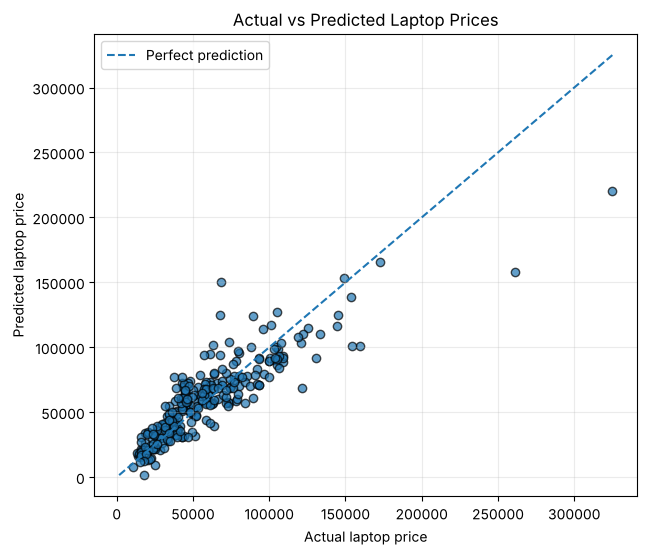

In [17]:
# Cell 17: Actual vs predicted scatter plot

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.7, edgecolor="black")

# Reference line from the smallest to the largest value
low = min(float(np.min(y_test)), float(np.min(y_pred)))
high = max(float(np.max(y_test)), float(np.max(y_pred)))
plt.plot([low, high], [low, high], linestyle="--", label="Perfect prediction")

plt.xlabel("Actual laptop price")
plt.ylabel("Predicted laptop price")
plt.title("Actual vs Predicted Laptop Prices")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

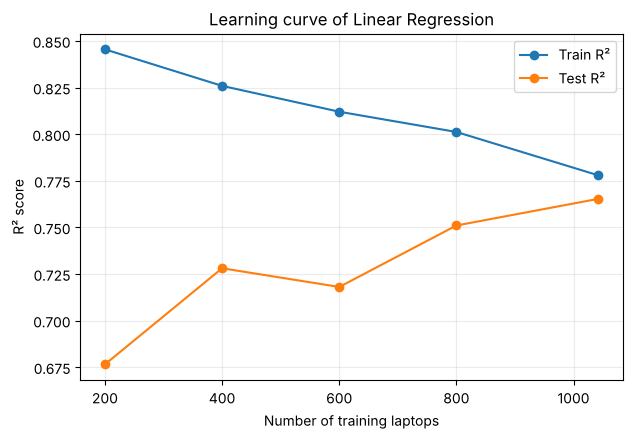

In [18]:
# Cell 18: Learning curve

sizes = [200, 400, 600, 800, len(X_train_scaled)]
train_scores = []
test_scores = []

for n in sizes:
    small_model = train_model(X_train_scaled[:n], y_train[:n])
    train_scores.append(r2_score(y_train[:n], small_model.predict(X_train_scaled[:n])))
    test_scores.append(r2_score(y_test, small_model.predict(X_test_scaled)))

plt.figure(figsize=(7, 4.5))
plt.plot(sizes, train_scores, marker="o", label="Train R²")
plt.plot(sizes, test_scores, marker="o", label="Test R²")
plt.xlabel("Number of training laptops")
plt.ylabel("R² score")
plt.title("Learning curve of Linear Regression")
plt.legend()
plt.grid(alpha=0.25)
plt.show()